# XGBoost Model for Network Traffic Classification

This notebook trains **one complete model**: an **XGBoost** classifier.

**Goal:** look at the time-based features of a network flow and predict what kind of traffic it is
(for example `CHAT`, `VOIP`, `VPN-FT`, ...). There are **14 classes** (7 normal + 7 VPN).

**Data:** ISCX VPN-nonVPN 2016, Scenario B. We use the processed train and test files that the team already made
in `data/processed/`. These files already have duplicates removed and use a group-aware 80/20 split,
so the same flow never appears in both train and test.

**What is XGBoost?** XGBoost (eXtreme Gradient Boosting) builds many **small decision trees one after another**.
Each new tree tries to **fix the mistakes** of the trees before it. The final answer is the sum of all trees.
It also has built-in **regularization** (penalties that stop trees from getting too complex), so it usually
overfits less than one big tree and is one of the strongest models for table data like ours.

**Why XGBoost here?**

- The class boundaries in this data are **non-linear**. Logistic Regression (linear) only reached about 0.35 macro F1.
- Tree models do not need feature scaling and handle very skewed features well.
- Boosting combines many weak trees into one strong model, so it is usually more accurate and more stable than a single tree.

**What this notebook does:**

1. Load the data and look at it
2. Train a simple baseline XGBoost model
3. Hyperparameter tuning with randomized search
4. Check class weights (balanced or not)
5. Cross validation of the best model
6. Learning curve
7. Boosting curve (score after each new tree)
8. Validation curves (`n_estimators`, `max_depth`, `learning_rate`)
9. Final test on the hold-out test set
10. Confusion matrix and class report
11. Feature importance
12. Run the tuned model on all four time windows
13. Compare with the team's Logistic Regression
14. Save the model

All results are saved in a separate folder: **`reports/results/xgboost/`**

## 1. Import libraries

In [1]:
import json
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance
from sklearn.model_selection import (
    StratifiedGroupKFold,
    RandomizedSearchCV,
    cross_validate,
    learning_curve,
    validation_curve,
)
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
print("XGBoost version:", xgb.__version__)

XGBoost version: 3.2.0


## 2. Settings and folders

Here we set the main settings in one place.

- `TIMEOUT = 15` : we use the 15 second time window for the main work (the team also used 15s as the main dataset).
- `TASK = "14class"` : 14 traffic classes.
- `SEED = 42` : fixed random seed so results are the same every time.
- `N_FOLDS = 5` : 5-fold cross validation.
- `N_ITER = 40` : number of random settings tried during tuning. XGBoost is slower than a single tree, so we try fewer.

`BASE_PARAMS` are settings that are always the same:

- `tree_method="hist"` : a fast way to build trees
- `eval_metric="mlogloss"` : multi-class log loss, the error XGBoost watches while training
- `n_jobs=1` : each model uses one CPU core, so the search can run many models at the same time

The notebook finds the project folder by itself, so it works if you run it from the `notebooks/` folder
or from the project folder. If the results folder does not exist, it is created.

In [2]:
TIMEOUT = 15
TASK = "14class"
SEED = 42
N_FOLDS = 5
N_ITER = 40
ALL_TIMEOUTS = [15, 30, 60, 120]
TARGET = "label"

FEATURES = [
    "duration", "min_fiat", "min_biat", "max_fiat", "max_biat", "mean_fiat",
    "mean_biat", "flowPktsPerSecond", "flowBytesPerSecond", "min_flowiat",
    "max_flowiat", "mean_flowiat", "std_flowiat", "min_active", "mean_active",
    "max_active", "std_active", "min_idle", "mean_idle", "max_idle", "std_idle",
]

BASE_PARAMS = {
    "objective": "multi:softprob",
    "tree_method": "hist",
    "eval_metric": "mlogloss",
    "random_state": SEED,
    "n_jobs": 1,
}

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
OUT_DIR = PROJECT_ROOT / "reports" / "results" / "xgboost"
FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
MODEL_DIR = OUT_DIR / "model"

for folder in [FIG_DIR, TAB_DIR, MODEL_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT_ROOT)
print("Results folder:", OUT_DIR)

Project folder: C:\Users\suner\Downloads\ml\ML-Traffic-Classification
Results folder: C:\Users\suner\Downloads\ml\ML-Traffic-Classification\reports\results\xgboost


## 3. Load the data

We load the train and test files. Each file has:

- 21 feature columns
- `label` : the traffic class (what we want to predict)
- `group_id` : rows with exactly the same features share the same id
- `conflict_flag` : 1 if the same features appear with more than one label

We keep `group_id` because we use it in cross validation, so the same flow does not end up in both the
training fold and the validation fold.

**Label encoding:** XGBoost needs the classes as numbers (0, 1, 2, ...), not text.
`LabelEncoder` turns `BROWSING` into 0, `CHAT` into 1, and so on. We fit it on the training labels only
and use it to turn the numbers back into class names for the reports.

In [3]:
def load_split(timeout, task=TASK):
    train = pd.read_csv(DATA_DIR / f"{task}_{timeout}s_train.csv")
    test = pd.read_csv(DATA_DIR / f"{task}_{timeout}s_test.csv")
    return train, test

train_df, test_df = load_split(TIMEOUT)

X_train = train_df[FEATURES]
X_test = test_df[FEATURES]
groups_train = train_df["group_id"]

encoder = LabelEncoder().fit(train_df[TARGET])
CLASSES = list(encoder.classes_)
y_train = encoder.transform(train_df[TARGET])
y_test = encoder.transform(test_df[TARGET])

print("Train shape:", X_train.shape)
print("Test shape :", X_test.shape)
print("Number of classes:", len(CLASSES))
print("Missing values in train:", int(X_train.isnull().sum().sum()))
print("Missing values in test :", int(X_test.isnull().sum().sum()))
print("Conflict rows in train:", int(train_df["conflict_flag"].sum()))
print("Conflict rows in test :", int(test_df["conflict_flag"].sum()))
print()
print("Label codes:", dict(zip(CLASSES, range(len(CLASSES)))))
train_df.head()

Train shape: (14459, 21)
Test shape : (3615, 21)
Number of classes: 14
Missing values in train: 0
Missing values in test : 0
Conflict rows in train: 82
Conflict rows in test : 18

Label codes: {'BROWSING': 0, 'CHAT': 1, 'FT': 2, 'MAIL': 3, 'P2P': 4, 'STREAMING': 5, 'VOIP': 6, 'VPN-BROWSING': 7, 'VPN-CHAT': 8, 'VPN-FT': 9, 'VPN-MAIL': 10, 'VPN-P2P': 11, 'VPN-STREAMING': 12, 'VPN-VOIP': 13}


,duration,min_fiat,min_biat,max_fiat,max_biat,mean_fiat,mean_biat,flowPktsPerSecond,flowBytesPerSecond,min_flowiat,max_flowiat,mean_flowiat,std_flowiat,min_active,mean_active,max_active,std_active,min_idle,mean_idle,max_idle,std_idle,label,group_id,conflict_flag
0,9368711.0,1564818.0,1549373.0,190205.285714,203290.456522,389822.391917,370323.719754,10.353612,4802.688438,4.0,1523088.0,97590.739583,267600.198443,1871488.0,1.983656e+06,2195089.0,1.832197e+05,1234883.0,1420565.0,1523088.0,161096.539275,CHAT,0,0
1,7340238.0,1567554.0,1527893.0,165686.977273,186914.846154,317267.548742,304370.651301,11.580006,4340.186245,4.0,1517774.0,87383.785714,221462.862028,1491627.0,3.572433e+06,5653239.0,2.942704e+06,1131498.0,1324636.0,1517774.0,273138.379008,CHAT,1,0
2,4644225.0,1270547.0,1079974.0,165865.178571,195302.130435,329473.126261,300492.588227,11.412022,4161.512416,15.0,1079974.0,89312.019231,217475.425246,1758922.0,1.758922e+06,1758922.0,0.000000e+00,1079974.0,1079974.0,1079974.0,0.000000,CHAT,2,0
3,4978735.0,2492050.0,2457286.0,239543.250000,276596.388889,612435.304238,628339.573544,8.034169,3918.666087,8.0,2441990.0,127659.871795,436959.716436,1710925.0,2.382905e+06,3054885.0,9.503232e+05,1346073.0,1894031.5,2441990.0,774930.342317,CHAT,3,0
4,11838189.0,3094089.0,3093543.0,243766.500000,295954.725000,599721.781709,625632.703972,7.602514,2802.540152,10.0,3042717.0,133013.359551,436129.639296,1747431.0,2.400446e+06,3240696.0,6.232744e+05,1394455.0,1983227.0,3042717.0,725987.829075,CHAT,4,0


## 4. Look at the class balance

Some classes have many rows (like `BROWSING` and `VOIP`) and some have very few (like `MAIL`).
This is called **class imbalance**. Because of this, plain accuracy can look good even if small classes
are predicted badly. So our main score is **macro F1**, which gives every class the same weight.

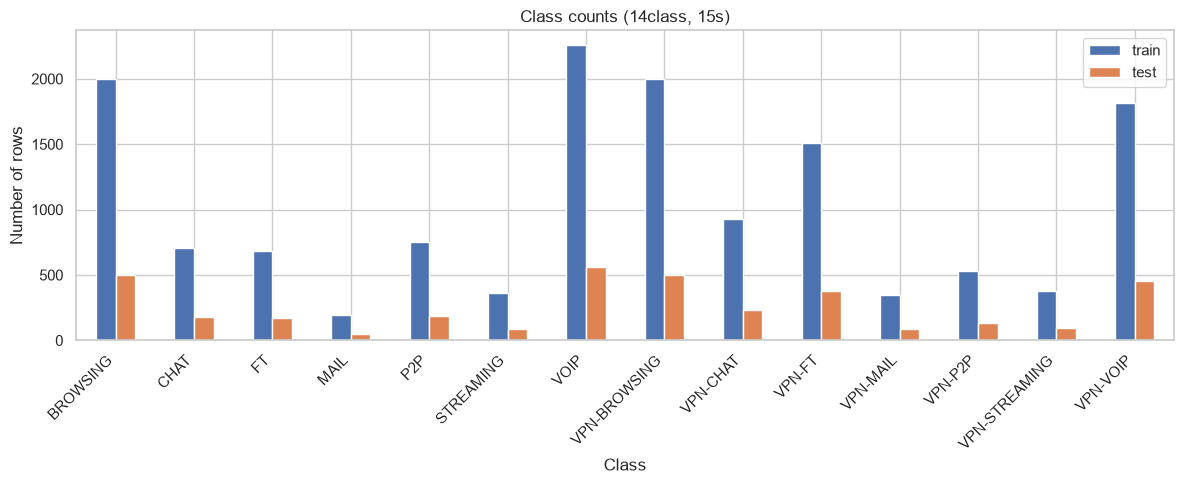

,train,test,train_%
label,,,
BROWSING,2000,500,13.83
CHAT,710,177,4.91
FT,685,172,4.74
MAIL,191,47,1.32
P2P,753,188,5.21
STREAMING,360,90,2.49
VOIP,2257,564,15.61
VPN-BROWSING,2000,500,13.83
VPN-CHAT,926,232,6.40


In [4]:
class_counts = pd.DataFrame({
    "train": train_df[TARGET].value_counts(),
    "test": test_df[TARGET].value_counts(),
}).loc[CLASSES]
class_counts["train_%"] = (100 * class_counts["train"] / class_counts["train"].sum()).round(2)
class_counts.to_csv(TAB_DIR / "class_counts.csv")

fig, ax = plt.subplots(figsize=(12, 5))
class_counts[["train", "test"]].plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.set_title(f"Class counts ({TASK}, {TIMEOUT}s)")
ax.set_xlabel("Class")
ax.set_ylabel("Number of rows")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FIG_DIR / "class_counts.png", dpi=200, bbox_inches="tight")
plt.show()

class_counts

## 5. Quick look at the features

XGBoost is made of decision trees, and trees only split values with simple rules like `duration < 5000`.
So we do **not** need to scale the features. Below is a short summary of each feature.
Some features have `-1` values. The team checked these and kept them, so we keep them too.

In [5]:
feature_summary = X_train.describe().T
feature_summary.to_csv(TAB_DIR / "feature_summary.csv")
feature_summary

,count,mean,std,min,25%,50%,75%,max
duration,14459.0,1.015701e+07,1.428622e+07,0.0,612652.500000,1.182602e+07,1.496303e+07,6.014050e+08
min_fiat,14459.0,3.467052e+06,1.121891e+07,-1.0,27975.000000,3.237810e+05,4.438964e+06,3.035957e+08
min_biat,14459.0,2.912495e+06,8.946455e+06,-1.0,25250.000000,3.522600e+05,4.406240e+06,6.001097e+08
max_fiat,14459.0,1.036727e+06,3.298948e+06,0.0,17615.478000,6.853200e+04,5.631879e+05,1.520000e+08
max_biat,14459.0,9.369807e+05,2.489874e+06,0.0,10660.900000,4.596370e+04,5.142301e+05,4.000000e+07
mean_fiat,14459.0,8.905535e+05,4.629786e+06,0.0,585.386719,1.336213e+04,6.642229e+05,2.150000e+08
mean_biat,14459.0,6.247219e+05,2.465725e+06,0.0,573.464300,1.481586e+04,5.984849e+05,9.800000e+07
flowPktsPerSecond,14459.0,1.378837e+03,1.145914e+04,0.0,3.230075,1.237624e+01,1.006952e+02,6.666667e+05
flowBytesPerSecond,14459.0,4.170514e+05,8.754578e+06,0.0,467.641391,2.866629e+03,1.352865e+04,6.170000e+08
min_flowiat,14459.0,4.264978e+04,4.499808e+05,-1247.0,4.000000,1.800000e+01,1.940000e+02,1.891990e+07


## 6. Evaluation helper

This small function gives all the scores we care about in one table:

- **Accuracy** : how many predictions are correct
- **Balanced accuracy** : average recall of each class
- **Macro precision / recall / F1** : average over classes, every class has the same weight
- **Weighted F1** : average over classes, weighted by class size
- **MCC** : Matthews correlation coefficient, a strong single score for multi-class problems

We also make the cross validation splitter. `StratifiedGroupKFold` keeps the class mix the same in every fold
(**stratified**) and never puts the same `group_id` in two folds (**group**), so there is no leakage.

In [6]:
def get_scores(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "macro_precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }

def cv_summary(cv_result):
    return pd.DataFrame({
        metric: {
            "train_mean": cv_result[f"train_{metric}"].mean(),
            "val_mean": cv_result[f"test_{metric}"].mean(),
            "val_std": cv_result[f"test_{metric}"].std(),
        }
        for metric in SCORING
    }).T

cv_splitter = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

SCORING = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro",
    "weighted_f1": "f1_weighted",
}

## 7. Baseline XGBoost

First we train XGBoost with the **default settings** (100 trees, depth 6, learning rate 0.3).
This gives us a starting point. Later we will check if tuning makes it better.

We test it with 5-fold cross validation on the **training data only**. The test set is kept aside until the end.

In [7]:
baseline_model = XGBClassifier(**BASE_PARAMS)

start = time.time()
baseline_cv = cross_validate(
    baseline_model, X_train, y_train,
    groups=groups_train, cv=cv_splitter,
    scoring=SCORING, return_train_score=True, n_jobs=-1,
)
print(f"Time: {time.time() - start:.1f} s")

baseline_cv_table = cv_summary(baseline_cv)
baseline_cv_table.to_csv(TAB_DIR / "baseline_cv_scores.csv")
baseline_cv_table.round(4)

Time: 21.0 s


,train_mean,val_mean,val_std
accuracy,0.9878,0.8467,0.0028
balanced_accuracy,0.9794,0.8141,0.0059
macro_f1,0.9780,0.8187,0.0055
weighted_f1,0.9879,0.8465,0.0027


Look at the gap between the train score and the validation score. A big gap means the model **overfits**:
it learns the training data too well and does worse on new data. Tuning tries to find settings with a
higher validation score and a smaller gap.

## 8. Hyperparameter tuning

We use **RandomizedSearchCV**. It tries `N_ITER` random combinations of settings and checks each one
with 5-fold group-aware cross validation. The best one is chosen by **macro F1**.

Settings we search:

| Setting | What it means |
|---|---|
| `n_estimators` | number of trees (boosting rounds) |
| `max_depth` | how deep each tree can grow |
| `learning_rate` | how much each new tree is allowed to change the answer. Small = slow but careful |
| `subsample` | share of rows each tree sees (adds randomness, reduces overfitting) |
| `colsample_bytree` | share of features each tree sees |
| `min_child_weight` | minimum "amount of data" needed in a leaf. Bigger = simpler trees |
| `gamma` | minimum gain needed to make a split. Bigger = fewer splits |
| `reg_lambda` | L2 regularization (penalty on large leaf values) |
| `reg_alpha` | L1 regularization |

This step takes the most time.

In [8]:
param_space = {
    "n_estimators": [200, 300, 400, 600, 800],
    "max_depth": [3, 4, 5, 6, 8, 10],
    "learning_rate": [0.03, 0.05, 0.1, 0.15, 0.2],
    "subsample": [0.6, 0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.5, 0.6, 0.7, 0.8, 1.0],
    "min_child_weight": [1, 3, 5, 7],
    "gamma": [0, 0.1, 0.3, 0.5, 1.0],
    "reg_lambda": [0.5, 1, 2, 5],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
}

search = RandomizedSearchCV(
    estimator=XGBClassifier(**BASE_PARAMS),
    param_distributions=param_space,
    n_iter=N_ITER,
    scoring=SCORING,
    refit="macro_f1",
    cv=cv_splitter,
    random_state=SEED,
    n_jobs=-1,
    return_train_score=True,
    verbose=1,
)

start = time.time()
search.fit(X_train, y_train, groups=groups_train)
print(f"Tuning time: {(time.time() - start) / 60:.1f} min")

def to_json_value(v):
    return v.item() if isinstance(v, np.generic) else v

best_params = {k: to_json_value(v) for k, v in search.best_params_.items()}
print("Best macro F1 (CV):", round(search.best_score_, 4))
print("Best settings:")
for key, value in best_params.items():
    print(f"  {key}: {value}")

Fitting 5 folds for each of 40 candidates, totalling 200 fits


Tuning time: 20.9 min
Best macro F1 (CV): 0.8223
Best settings:
  subsample: 0.6
  reg_lambda: 5
  reg_alpha: 0.5
  n_estimators: 400
  min_child_weight: 3
  max_depth: 10
  learning_rate: 0.2
  gamma: 0
  colsample_bytree: 0.7


### 8.1 All tuning results

The table shows the top settings that were tried, sorted from best to worst by validation macro F1.
The full list is saved as `tables/tuning_results.csv`.

In [9]:
tuning_results = pd.DataFrame(search.cv_results_)
keep_cols = [c for c in tuning_results.columns if c.startswith("param_")] + [
    "mean_train_macro_f1", "mean_test_macro_f1", "std_test_macro_f1",
    "mean_test_accuracy", "mean_test_balanced_accuracy", "mean_fit_time", "rank_test_macro_f1",
]
tuning_results = tuning_results[keep_cols].sort_values("rank_test_macro_f1")
tuning_results.to_csv(TAB_DIR / "tuning_results.csv", index=False)
tuning_results.head(10).round(4)

,param_subsample,param_reg_lambda,param_reg_alpha,param_n_estimators,param_min_child_weight,param_max_depth,param_learning_rate,param_gamma,param_colsample_bytree,mean_train_macro_f1,mean_test_macro_f1,std_test_macro_f1,mean_test_accuracy,mean_test_balanced_accuracy,mean_fit_time,rank_test_macro_f1
27,0.6,5.0,0.50,400,3,10,0.20,0.0,0.7,0.9755,0.8223,0.0080,0.8496,0.8193,88.9311,1
6,0.8,0.5,0.01,600,5,10,0.20,0.3,1.0,0.9710,0.8210,0.0050,0.8487,0.8178,81.0099,2
3,0.9,5.0,0.10,800,7,10,0.05,0.0,0.6,0.9669,0.8203,0.0048,0.8490,0.8160,149.3341,3
29,0.6,1.0,0.10,300,1,10,0.05,0.1,0.5,0.9732,0.8192,0.0043,0.8496,0.8143,86.6980,4
12,0.8,1.0,0.00,400,7,10,0.15,0.0,0.6,0.9756,0.8190,0.0032,0.8484,0.8144,81.4977,5
0,0.9,5.0,0.01,800,1,8,0.10,0.3,0.5,0.9552,0.8187,0.0074,0.8471,0.8137,107.9345,6
39,1.0,2.0,0.10,600,5,10,0.15,0.1,0.7,0.9579,0.8187,0.0051,0.8478,0.8143,44.5313,7
1,0.6,5.0,0.01,800,3,10,0.20,0.5,0.7,0.9570,0.8185,0.0049,0.8454,0.8149,92.0731,8
37,0.7,5.0,0.01,200,1,6,0.20,0.1,0.6,0.9694,0.8185,0.0048,0.8456,0.8133,43.6560,9
36,0.9,5.0,0.00,800,7,5,0.15,0.0,0.6,0.9748,0.8179,0.0040,0.8465,0.8136,125.8933,10


### 8.2 Tuning results as a chart

Each dot is one setting. A big gap between the train and validation dot means that setting overfits.

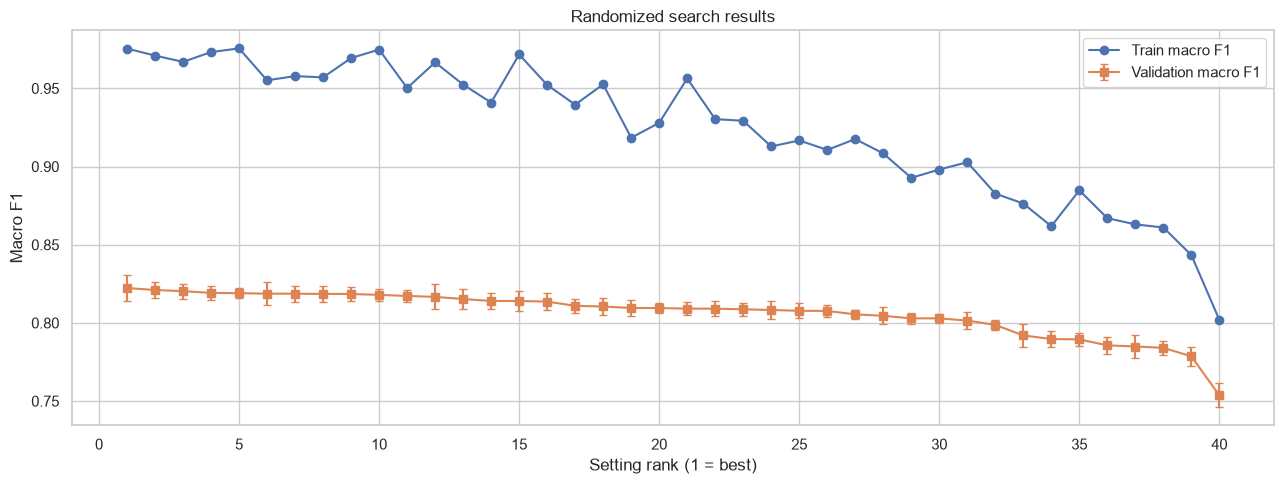

In [10]:
plot_df = tuning_results.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(plot_df.index + 1, plot_df["mean_train_macro_f1"], "o-", label="Train macro F1")
ax.errorbar(plot_df.index + 1, plot_df["mean_test_macro_f1"], yerr=plot_df["std_test_macro_f1"],
            fmt="s-", capsize=3, label="Validation macro F1")
ax.set_xlabel("Setting rank (1 = best)")
ax.set_ylabel("Macro F1")
ax.set_title("Randomized search results")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "tuning_results.png", dpi=200, bbox_inches="tight")
plt.show()

### 8.3 Which settings matter the most?

For the main settings we show the average validation macro F1 for each value.
This helps to explain *why* the best setting was chosen.

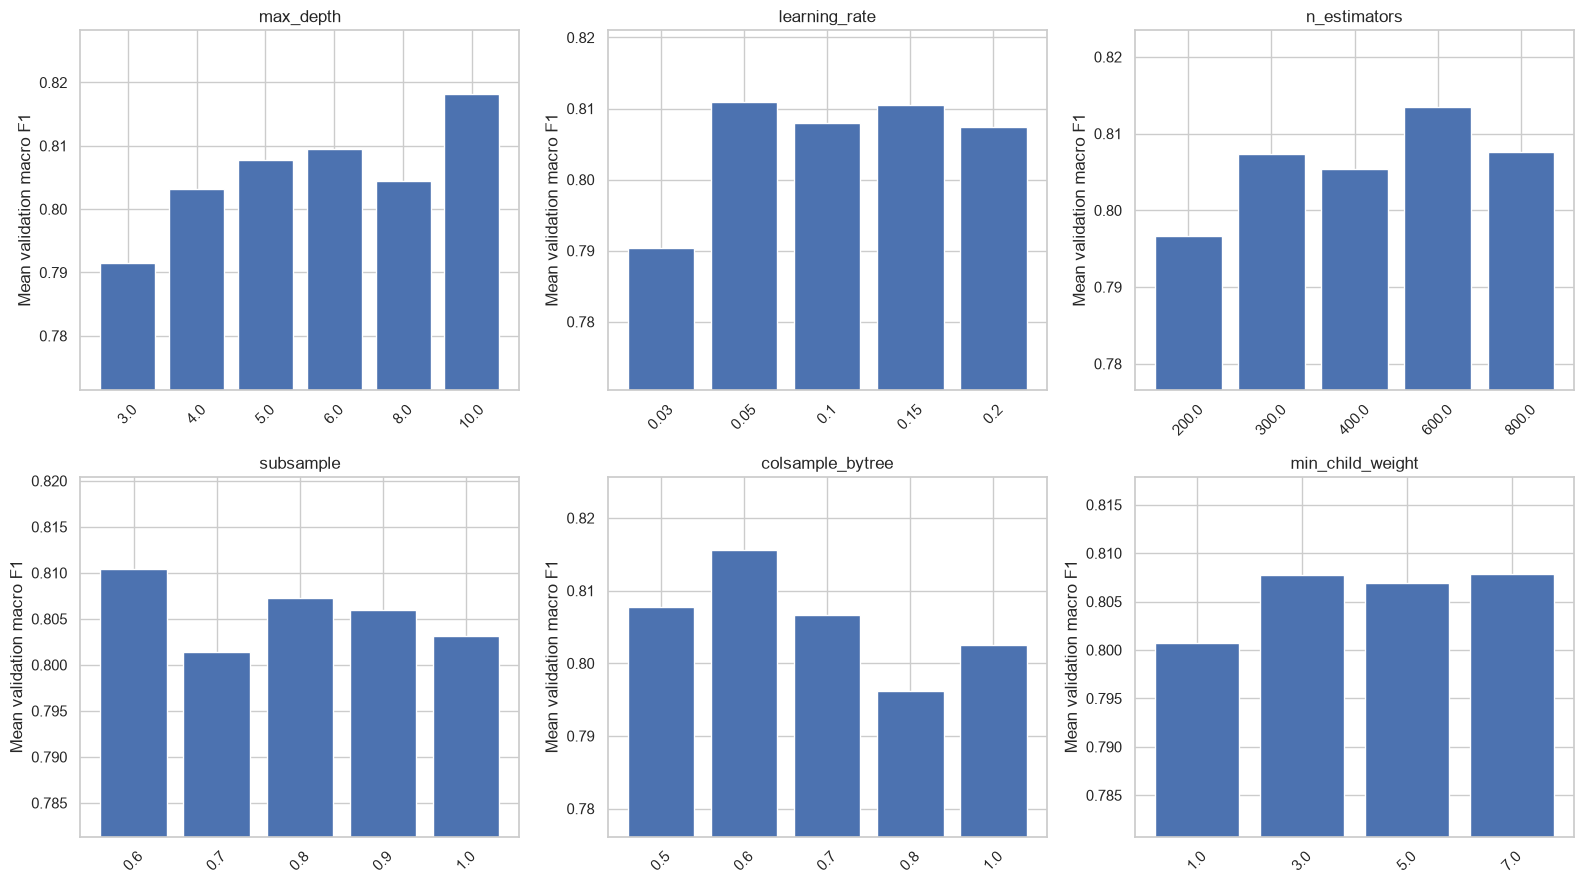

In [11]:
setting_names = ["max_depth", "learning_rate", "n_estimators", "subsample", "colsample_bytree", "min_child_weight"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, name in zip(axes.ravel(), setting_names):
    col = f"param_{name}"
    summary = (
        tuning_results.assign(value=tuning_results[col].astype(float))
        .groupby("value")["mean_test_macro_f1"].mean()
        .sort_index()
    )
    ax.bar([str(v) for v in summary.index], summary.values, color="#4C72B0")
    ax.set_title(name)
    ax.set_ylabel("Mean validation macro F1")
    ax.set_ylim(summary.min() - 0.02, summary.max() + 0.01)
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / "tuning_setting_effects.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Class weights: balanced or not?

XGBoost does not have a simple `class_weight` setting like other scikit-learn models.
Instead we can give each training row a **sample weight**. With `balanced` weights, rows from small classes
(like `MAIL`) get a bigger weight, so the model pays more attention to them.

We compare the tuned model **with** and **without** balanced weights using cross validation,
and keep the version with the higher validation macro F1. The weights are computed inside each fold,
so this is still fair.

In [12]:
train_weights = compute_sample_weight("balanced", y_train)

tuned_plain_cv = cross_validate(
    XGBClassifier(**BASE_PARAMS, **best_params), X_train, y_train,
    groups=groups_train, cv=cv_splitter,
    scoring=SCORING, return_train_score=True, n_jobs=-1,
)
tuned_weighted_cv = cross_validate(
    XGBClassifier(**BASE_PARAMS, **best_params), X_train, y_train,
    groups=groups_train, cv=cv_splitter,
    scoring=SCORING, return_train_score=True, n_jobs=-1,
    params={"sample_weight": train_weights},
)

weight_compare = pd.DataFrame({
    "no_weights": cv_summary(tuned_plain_cv)["val_mean"],
    "balanced_weights": cv_summary(tuned_weighted_cv)["val_mean"],
})
weight_compare["difference"] = weight_compare["balanced_weights"] - weight_compare["no_weights"]
weight_compare.to_csv(TAB_DIR / "class_weight_check.csv")

USE_BALANCED = weight_compare.loc["macro_f1", "balanced_weights"] > weight_compare.loc["macro_f1", "no_weights"]
FIT_PARAMS = {"sample_weight": train_weights} if USE_BALANCED else {}
best_params["sample_weight"] = "balanced" if USE_BALANCED else "none"
model_params = {k: v for k, v in best_params.items() if k != "sample_weight"}

with open(OUT_DIR / "best_params.json", "w") as f:
    json.dump(best_params, f, indent=2)

print("Use balanced sample weights:", USE_BALANCED)
weight_compare.round(4)

Use balanced sample weights: False


,no_weights,balanced_weights,difference
accuracy,0.8496,0.8469,-0.0028
balanced_accuracy,0.8193,0.8269,0.0076
macro_f1,0.8223,0.8202,-0.0021
weighted_f1,0.8496,0.8471,-0.0025


## 10. Cross validation of the best model

Now we take the final settings (best hyperparameters + the chosen weight option) and look at the score of
**each fold**. This shows how stable the model is. A small standard deviation means the model gives
similar results on different parts of the data.

In [13]:
tuned_cv = tuned_weighted_cv if USE_BALANCED else tuned_plain_cv

fold_table = pd.DataFrame({
    "fold": range(1, N_FOLDS + 1),
    **{f"train_{m}": tuned_cv[f"train_{m}"] for m in SCORING},
    **{f"val_{m}": tuned_cv[f"test_{m}"] for m in SCORING},
})
fold_table.to_csv(TAB_DIR / "tuned_cv_folds.csv", index=False)

tuned_cv_table = cv_summary(tuned_cv)
tuned_cv_table.to_csv(TAB_DIR / "tuned_cv_scores.csv")

display(fold_table.round(4))
tuned_cv_table.round(4)

,fold,train_accuracy,train_balanced_accuracy,train_macro_f1,train_weighted_f1,val_accuracy,val_balanced_accuracy,val_macro_f1,val_weighted_f1
0,1,0.9872,0.9772,0.9763,0.9872,0.8575,0.8216,0.8271,0.8575
1,2,0.9876,0.9764,0.9758,0.9877,0.8444,0.8144,0.8151,0.8444
2,3,0.9868,0.9753,0.9748,0.9868,0.8434,0.8116,0.8156,0.8431
3,4,0.9871,0.9753,0.9752,0.9871,0.8465,0.8162,0.8180,0.8461
4,5,0.9869,0.9751,0.9752,0.9869,0.8565,0.8327,0.8358,0.8568


,train_mean,val_mean,val_std
accuracy,0.9871,0.8496,0.0061
balanced_accuracy,0.9759,0.8193,0.0074
macro_f1,0.9755,0.8223,0.0080
weighted_f1,0.9872,0.8496,0.0063


### 10.1 Score of each fold

This chart shows the validation score of each fold. If the bars are about the same height, the model is stable.

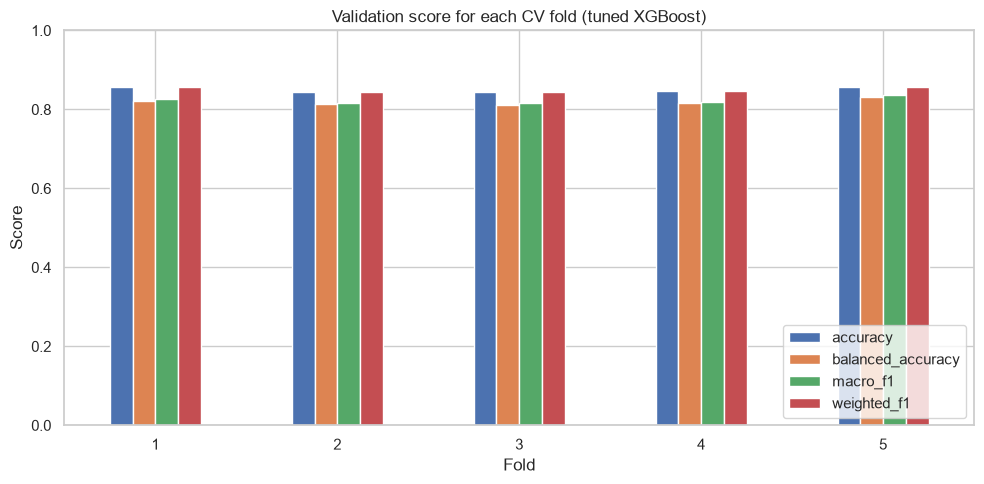

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
fold_plot = fold_table.set_index("fold")[[f"val_{m}" for m in SCORING]]
fold_plot.columns = list(SCORING)
fold_plot.plot(kind="bar", ax=ax)
ax.set_title("Validation score for each CV fold (tuned XGBoost)")
ax.set_xlabel("Fold")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "cv_folds.png", dpi=200, bbox_inches="tight")
plt.show()

### 10.2 Baseline vs tuned (cross validation)

Here we compare the default XGBoost and the tuned XGBoost using the cross validation scores.

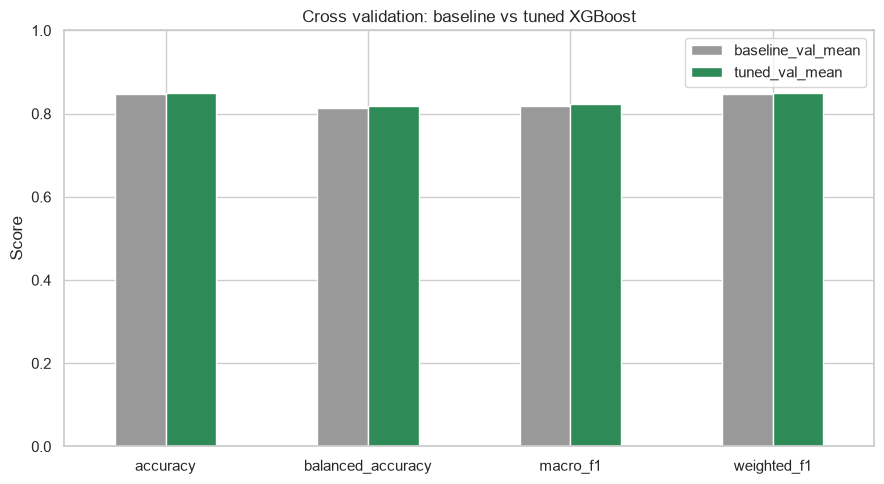

,baseline_val_mean,tuned_val_mean,baseline_train_mean,tuned_train_mean,val_change,baseline_gap,tuned_gap
accuracy,0.8467,0.8496,0.9878,0.9871,0.0030,0.1412,0.1375
balanced_accuracy,0.8141,0.8193,0.9794,0.9759,0.0052,0.1653,0.1565
macro_f1,0.8187,0.8223,0.9780,0.9755,0.0036,0.1592,0.1532
weighted_f1,0.8465,0.8496,0.9879,0.9872,0.0030,0.1413,0.1376


In [15]:
cv_compare = pd.DataFrame({
    "baseline_val_mean": baseline_cv_table["val_mean"],
    "tuned_val_mean": tuned_cv_table["val_mean"],
    "baseline_train_mean": baseline_cv_table["train_mean"],
    "tuned_train_mean": tuned_cv_table["train_mean"],
})
cv_compare["val_change"] = cv_compare["tuned_val_mean"] - cv_compare["baseline_val_mean"]
cv_compare["baseline_gap"] = cv_compare["baseline_train_mean"] - cv_compare["baseline_val_mean"]
cv_compare["tuned_gap"] = cv_compare["tuned_train_mean"] - cv_compare["tuned_val_mean"]
cv_compare.to_csv(TAB_DIR / "baseline_vs_tuned_cv.csv")

fig, ax = plt.subplots(figsize=(9, 5))
cv_compare[["baseline_val_mean", "tuned_val_mean"]].plot(kind="bar", ax=ax, color=["#999999", "#2E8B57"])
ax.set_title("Cross validation: baseline vs tuned XGBoost")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "baseline_vs_tuned_cv.png", dpi=200, bbox_inches="tight")
plt.show()

cv_compare.round(4)

## 11. Learning curve

A learning curve trains the model on bigger and bigger parts of the training data and shows the
train score and the validation score each time.

How to read it:

- If both lines are low and close → the model is too simple (**underfitting**).
- If the train line is high and the validation line is much lower → the model **overfits**.
- If the validation line is still going up at the end → **more data would help**.

We draw it for both the **baseline** and the **tuned** model.

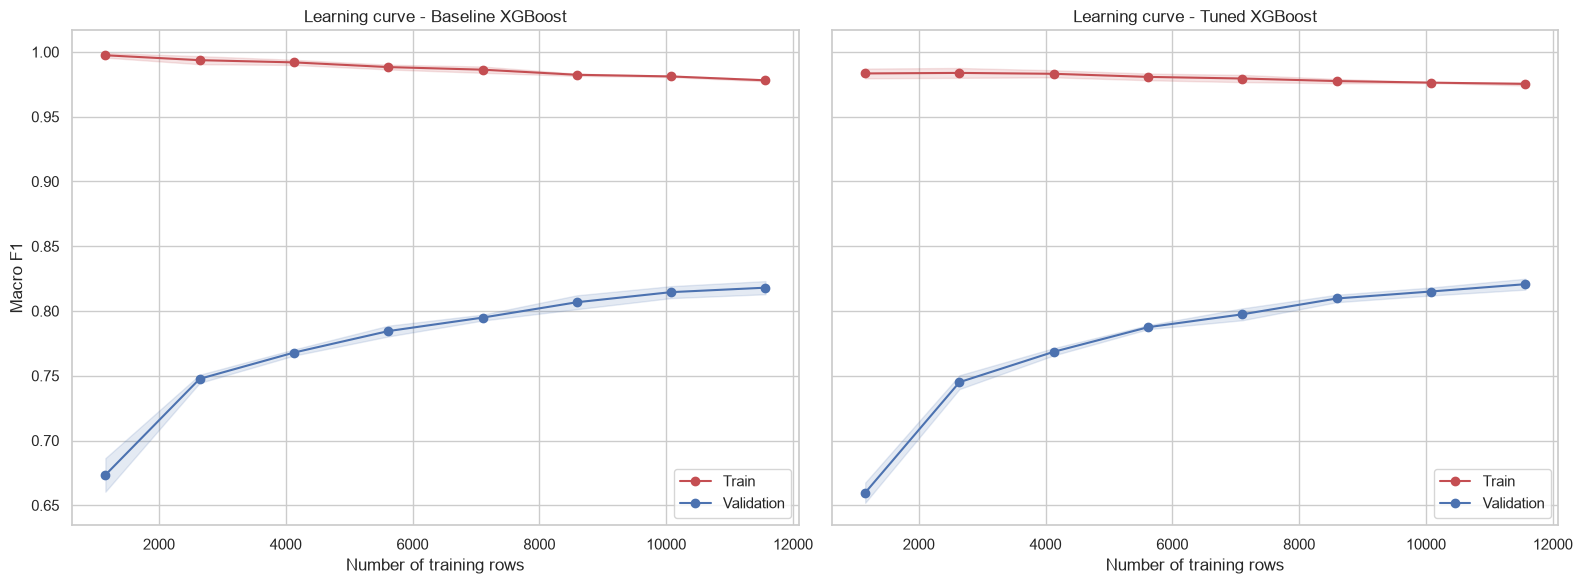

,train_size,train_mean,train_std,val_mean,val_std
0,1156,0.9834,0.0038,0.6597,0.0078
1,2643,0.9838,0.0038,0.7450,0.0053
2,4131,0.9831,0.0027,0.7685,0.0028
3,5618,0.9808,0.0026,0.7875,0.0015
4,7105,0.9795,0.0028,0.7975,0.0046
5,8592,0.9775,0.0016,0.8097,0.0029
6,10079,0.9763,0.0003,0.8151,0.0031
7,11567,0.9753,0.0012,0.8207,0.0042


In [16]:
def make_learning_curve(model, fit_params=None):
    sizes, tr, va = learning_curve(
        model, X_train, y_train,
        groups=groups_train, cv=cv_splitter,
        train_sizes=np.linspace(0.1, 1.0, 8),
        scoring="f1_macro", n_jobs=-1, shuffle=True, random_state=SEED,
        params=fit_params or None,
    )
    return pd.DataFrame({
        "train_size": sizes,
        "train_mean": tr.mean(axis=1), "train_std": tr.std(axis=1),
        "val_mean": va.mean(axis=1), "val_std": va.std(axis=1),
    })

lc_tuned = make_learning_curve(XGBClassifier(**BASE_PARAMS, **model_params), FIT_PARAMS)
lc_base = make_learning_curve(XGBClassifier(**BASE_PARAMS))
lc_tuned.to_csv(TAB_DIR / "learning_curve_tuned.csv", index=False)
lc_base.to_csv(TAB_DIR / "learning_curve_baseline.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
for ax, table, title in [(axes[0], lc_base, "Baseline XGBoost"), (axes[1], lc_tuned, "Tuned XGBoost")]:
    ax.plot(table["train_size"], table["train_mean"], "o-", color="#C44E52", label="Train")
    ax.fill_between(table["train_size"], table["train_mean"] - table["train_std"],
                    table["train_mean"] + table["train_std"], alpha=0.15, color="#C44E52")
    ax.plot(table["train_size"], table["val_mean"], "o-", color="#4C72B0", label="Validation")
    ax.fill_between(table["train_size"], table["val_mean"] - table["val_std"],
                    table["val_mean"] + table["val_std"], alpha=0.15, color="#4C72B0")
    ax.set_xlabel("Number of training rows")
    ax.set_title(f"Learning curve - {title}")
    ax.legend(loc="lower right")
axes[0].set_ylabel("Macro F1")
plt.tight_layout()
plt.savefig(FIG_DIR / "learning_curve.png", dpi=200, bbox_inches="tight")
plt.show()

lc_tuned.round(4)

## 12. Boosting curve (error after each tree)

XGBoost adds trees one by one. Here we watch how the error changes **after every new tree**.

We split the training data once more into a training part and a **validation part** (using the same
group-aware split, so there is no leakage). The test set is still not used.
We train the tuned model and record two errors after each tree:

- **mlogloss** : multi-class log loss (lower is better). It looks at how confident the predictions are.
- **merror** : share of wrong predictions (lower is better).

How to read it: the training error keeps going down. If the validation error stops going down,
or starts going up, adding more trees does not help any more (the model starts to overfit).

Number of trees used: 400
Round with the lowest validation log loss: 180


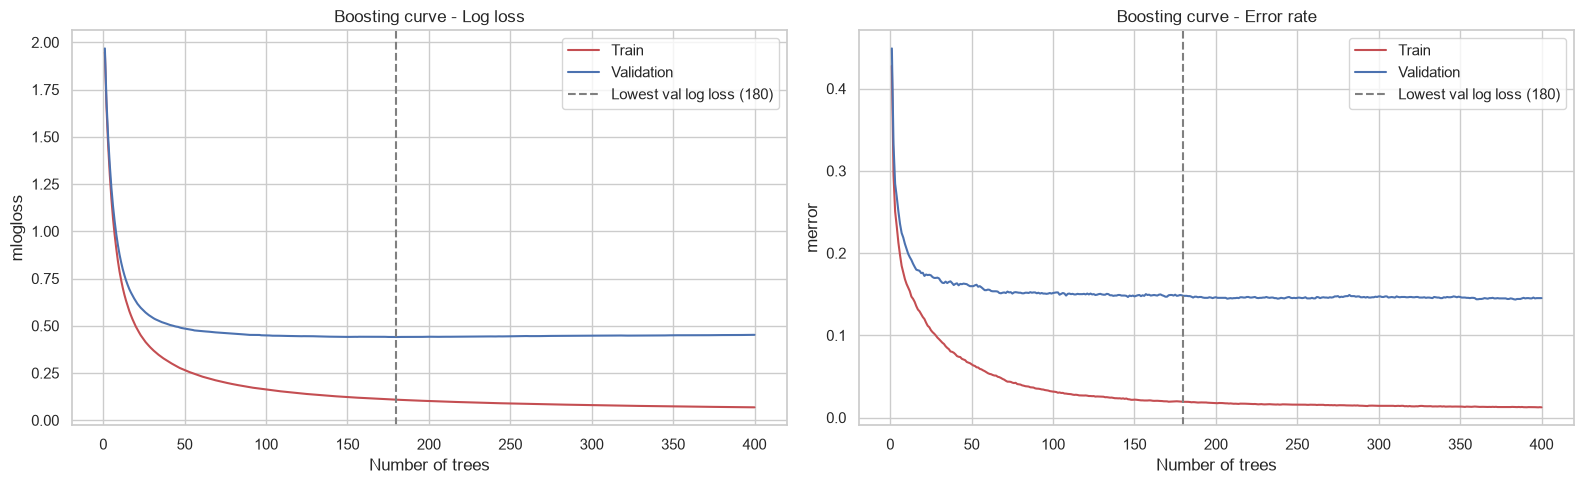

In [17]:
inner_train_idx, inner_val_idx = next(cv_splitter.split(X_train, y_train, groups=groups_train))
X_in, y_in = X_train.iloc[inner_train_idx], y_train[inner_train_idx]
X_val, y_val = X_train.iloc[inner_val_idx], y_train[inner_val_idx]

curve_params = {**BASE_PARAMS, **model_params, "eval_metric": ["mlogloss", "merror"], "n_jobs": -1}
curve_model = XGBClassifier(**curve_params)
curve_weights = compute_sample_weight("balanced", y_in) if USE_BALANCED else None
curve_model.fit(X_in, y_in, sample_weight=curve_weights,
                eval_set=[(X_in, y_in), (X_val, y_val)], verbose=False)

history = curve_model.evals_result()
boosting_table = pd.DataFrame({
    "round": np.arange(1, len(history["validation_0"]["mlogloss"]) + 1),
    "train_mlogloss": history["validation_0"]["mlogloss"],
    "val_mlogloss": history["validation_1"]["mlogloss"],
    "train_merror": history["validation_0"]["merror"],
    "val_merror": history["validation_1"]["merror"],
})
boosting_table.to_csv(TAB_DIR / "boosting_curve.csv", index=False)

best_round = int(boosting_table["val_mlogloss"].idxmin()) + 1
print("Number of trees used:", len(boosting_table))
print("Round with the lowest validation log loss:", best_round)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, metric, title in [(axes[0], "mlogloss", "Log loss"), (axes[1], "merror", "Error rate")]:
    ax.plot(boosting_table["round"], boosting_table[f"train_{metric}"], color="#C44E52", label="Train")
    ax.plot(boosting_table["round"], boosting_table[f"val_{metric}"], color="#4C72B0", label="Validation")
    ax.axvline(best_round, color="gray", linestyle="--", label=f"Lowest val log loss ({best_round})")
    ax.set_xlabel("Number of trees")
    ax.set_ylabel(metric)
    ax.set_title(f"Boosting curve - {title}")
    ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "boosting_curve.png", dpi=200, bbox_inches="tight")
plt.show()

## 13. Validation curves

A validation curve changes **one** setting and keeps the others at their best values.
It shows clearly where the model starts to overfit (train score goes up, validation score stops improving
or goes down) and where it underfits (both scores are low).

We check the three most important XGBoost settings:

- `n_estimators` : number of trees
- `max_depth` : depth of each tree
- `learning_rate` : size of each step

Time: 15.5 min


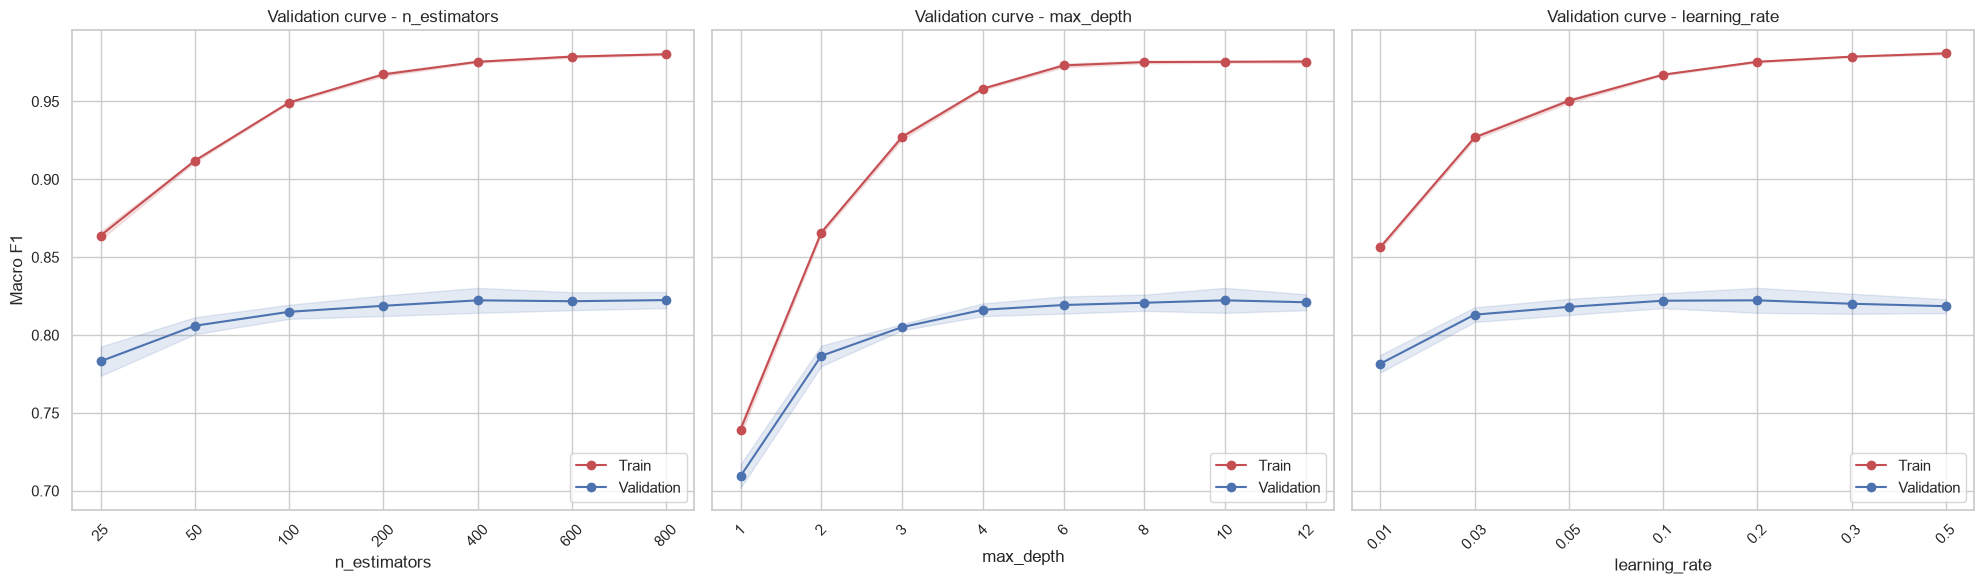

,max_depth,train_mean,train_std,val_mean,val_std
0,1,0.7394,0.0034,0.7094,0.0076
1,2,0.8658,0.0014,0.7867,0.0066
2,3,0.9271,0.0017,0.8051,0.0020
3,4,0.9582,0.0008,0.8162,0.0041
4,6,0.9731,0.0012,0.8193,0.0055
5,8,0.9753,0.0008,0.8208,0.0052
6,10,0.9755,0.0005,0.8223,0.0080
7,12,0.9756,0.0008,0.8211,0.0051


In [18]:
def make_validation_curve(param_name, values):
    params = {k: v for k, v in model_params.items() if k != param_name}
    tr, va = validation_curve(
        XGBClassifier(**BASE_PARAMS, **params),
        X_train, y_train, groups=groups_train,
        param_name=param_name, param_range=values,
        cv=cv_splitter, scoring="f1_macro", n_jobs=-1,
        params=FIT_PARAMS or None,
    )
    return pd.DataFrame({
        param_name: [str(v) for v in values],
        "train_mean": tr.mean(axis=1), "train_std": tr.std(axis=1),
        "val_mean": va.mean(axis=1), "val_std": va.std(axis=1),
    })

start = time.time()
curves = {
    "n_estimators": make_validation_curve("n_estimators", [25, 50, 100, 200, 400, 600, 800]),
    "max_depth": make_validation_curve("max_depth", [1, 2, 3, 4, 6, 8, 10, 12]),
    "learning_rate": make_validation_curve("learning_rate", [0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5]),
}
print(f"Time: {(time.time() - start) / 60:.1f} min")

fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharey=True)
for ax, (name, table) in zip(axes, curves.items()):
    table.to_csv(TAB_DIR / f"validation_curve_{name}.csv", index=False)
    x = np.arange(len(table))
    ax.plot(x, table["train_mean"], "o-", color="#C44E52", label="Train")
    ax.fill_between(x, table["train_mean"] - table["train_std"],
                    table["train_mean"] + table["train_std"], alpha=0.15, color="#C44E52")
    ax.plot(x, table["val_mean"], "o-", color="#4C72B0", label="Validation")
    ax.fill_between(x, table["val_mean"] - table["val_std"],
                    table["val_mean"] + table["val_std"], alpha=0.15, color="#4C72B0")
    ax.set_xticks(x)
    ax.set_xticklabels(table[name], rotation=45)
    ax.set_xlabel(name)
    ax.set_title(f"Validation curve - {name}")
    ax.legend(loc="lower right")
axes[0].set_ylabel("Macro F1")
plt.tight_layout()
plt.savefig(FIG_DIR / "validation_curves.png", dpi=200, bbox_inches="tight")
plt.show()

curves["max_depth"].round(4)

## 14. Train the final model and test it

Now we train the tuned XGBoost on the **full training set** and test it **once** on the hold-out
test set. The test set was never used for tuning, so this is a fair check of how the model works on new data.
We also train and test the baseline model, to see how much tuning helped.

In [19]:
final_model = XGBClassifier(**{**BASE_PARAMS, "n_jobs": -1}, **model_params)

start = time.time()
final_model.fit(X_train, y_train, **FIT_PARAMS)
print(f"Training time: {time.time() - start:.1f} s")

y_train_pred = final_model.predict(X_train)
y_test_pred = final_model.predict(X_test)

baseline_final = XGBClassifier(**{**BASE_PARAMS, "n_jobs": -1}).fit(X_train, y_train)
y_test_pred_base = baseline_final.predict(X_test)

test_scores = pd.DataFrame({
    "tuned_train": get_scores(y_train, y_train_pred),
    "tuned_test": get_scores(y_test, y_test_pred),
    "baseline_test": get_scores(y_test, y_test_pred_base),
})
test_scores.to_csv(TAB_DIR / "test_scores.csv")
test_scores.round(4)

Training time: 24.7 s


,tuned_train,tuned_test,baseline_test
accuracy,0.9868,0.8606,0.8539
balanced_accuracy,0.9756,0.8209,0.8108
macro_precision,0.9751,0.8288,0.8237
macro_recall,0.9756,0.8209,0.8108
macro_f1,0.9752,0.8235,0.8159
weighted_f1,0.9868,0.8600,0.8536
mcc,0.9853,0.8443,0.8369


## 15. Class by class report

This shows precision, recall and F1 for **each class** on the test set.

- **Precision** : when the model says "class X", how often it is right
- **Recall** : of all real "class X" rows, how many the model found
- **Support** : number of test rows in that class

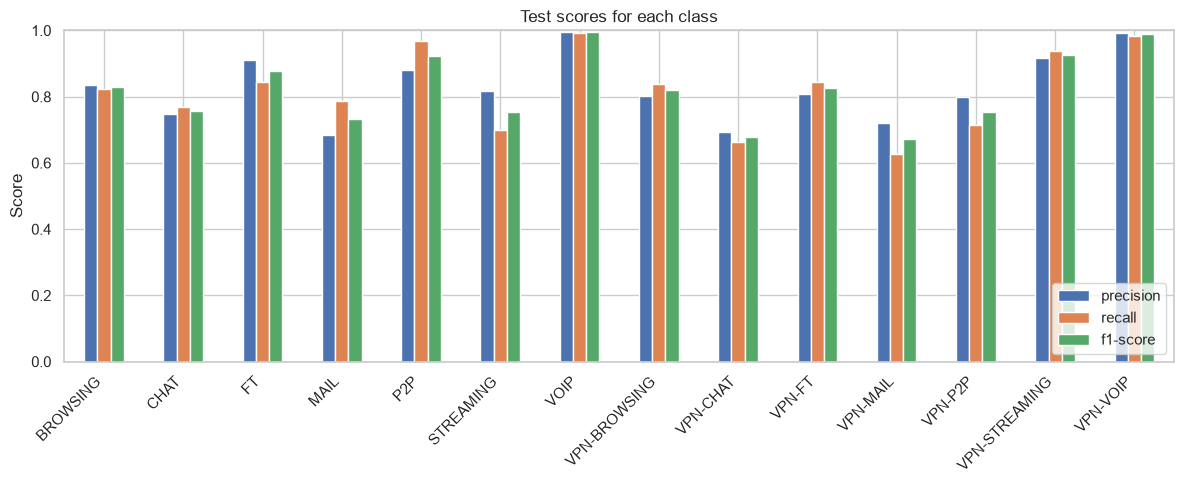

,precision,recall,f1-score,support
BROWSING,0.834,0.824,0.829,500.000
CHAT,0.747,0.768,0.758,177.000
FT,0.912,0.843,0.876,172.000
MAIL,0.685,0.787,0.733,47.000
P2P,0.879,0.968,0.922,188.000
STREAMING,0.818,0.700,0.754,90.000
VOIP,0.996,0.993,0.995,564.000
VPN-BROWSING,0.801,0.838,0.819,500.000
VPN-CHAT,0.694,0.664,0.678,232.000
VPN-FT,0.809,0.844,0.826,377.000


In [20]:
y_test_names = encoder.inverse_transform(y_test)
y_pred_names = encoder.inverse_transform(y_test_pred)

report = classification_report(y_test_names, y_pred_names, labels=CLASSES, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
report_df.to_csv(TAB_DIR / "classification_report.csv")

per_class = report_df.loc[CLASSES, ["precision", "recall", "f1-score"]]
fig, ax = plt.subplots(figsize=(12, 5))
per_class.plot(kind="bar", ax=ax)
ax.set_title("Test scores for each class")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "per_class_scores.png", dpi=200, bbox_inches="tight")
plt.show()

report_df.round(3)

## 16. Confusion matrix

Rows are the **real** class and columns are the **predicted** class. The numbers on the diagonal are correct
predictions. Numbers outside the diagonal show which classes get mixed up.

We show two versions:

- **Counts** : number of rows
- **Normalized** : each row divided by its total, so each row shows the recall of that class

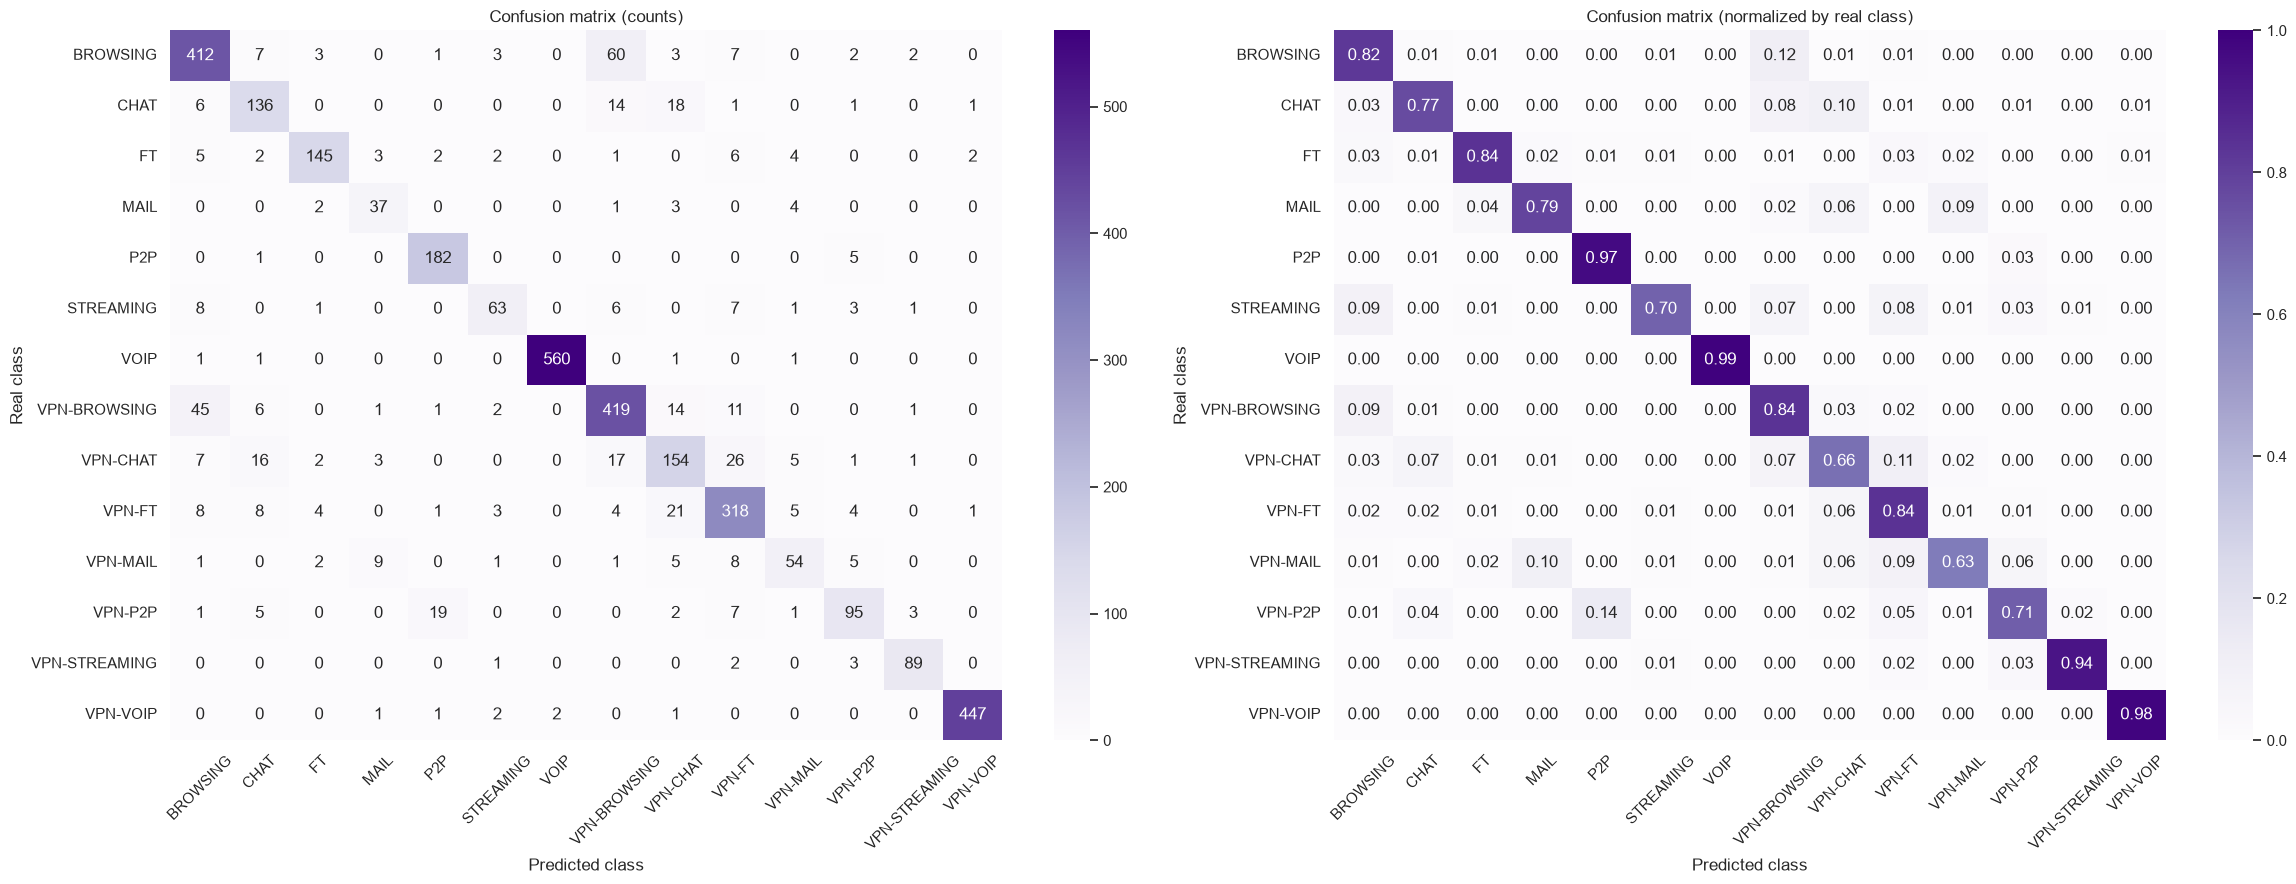

In [21]:
cm = confusion_matrix(y_test_names, y_pred_names, labels=CLASSES)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

pd.DataFrame(cm, index=CLASSES, columns=CLASSES).to_csv(TAB_DIR / "confusion_matrix.csv")

fig, axes = plt.subplots(1, 2, figsize=(24, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("Confusion matrix (counts)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1])
axes[1].set_title("Confusion matrix (normalized by real class)")
for ax in axes:
    ax.set_xlabel("Predicted class")
    ax.set_ylabel("Real class")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

### 16.1 Most common mistakes

This table lists the pairs of classes that the model mixes up the most.

In [22]:
mistakes = (
    pd.DataFrame(cm, index=CLASSES, columns=CLASSES)
    .stack()
    .rename_axis(["real", "predicted"])
    .reset_index(name="count")
)
mistakes = mistakes[mistakes["real"] != mistakes["predicted"]].sort_values("count", ascending=False)
mistakes["share_of_real_class_%"] = (
    100 * mistakes["count"] / mistakes["real"].map(pd.Series(y_test_names).value_counts())
).round(1)
mistakes.to_csv(TAB_DIR / "top_mistakes.csv", index=False)
mistakes.head(10)

,real,predicted,count,share_of_real_class_%
7,BROWSING,VPN-BROWSING,60,12.0
98,VPN-BROWSING,BROWSING,45,9.0
121,VPN-CHAT,VPN-FT,26,11.2
134,VPN-FT,VPN-CHAT,21,5.6
158,VPN-P2P,P2P,19,14.3
22,CHAT,VPN-CHAT,18,10.2
119,VPN-CHAT,VPN-BROWSING,17,7.3
113,VPN-CHAT,CHAT,16,6.9
21,CHAT,VPN-BROWSING,14,7.9
106,VPN-BROWSING,VPN-CHAT,14,2.8


## 17. Feature importance

We look at which features help the model the most, in two ways:

- **Gain importance** : built into XGBoost. It shows how much each feature improves the trees when it is used in a split.
- **Permutation importance** : we shuffle one feature in the test set and see how much macro F1 drops.
  A bigger drop means the feature is more important. This is the more trusted method.

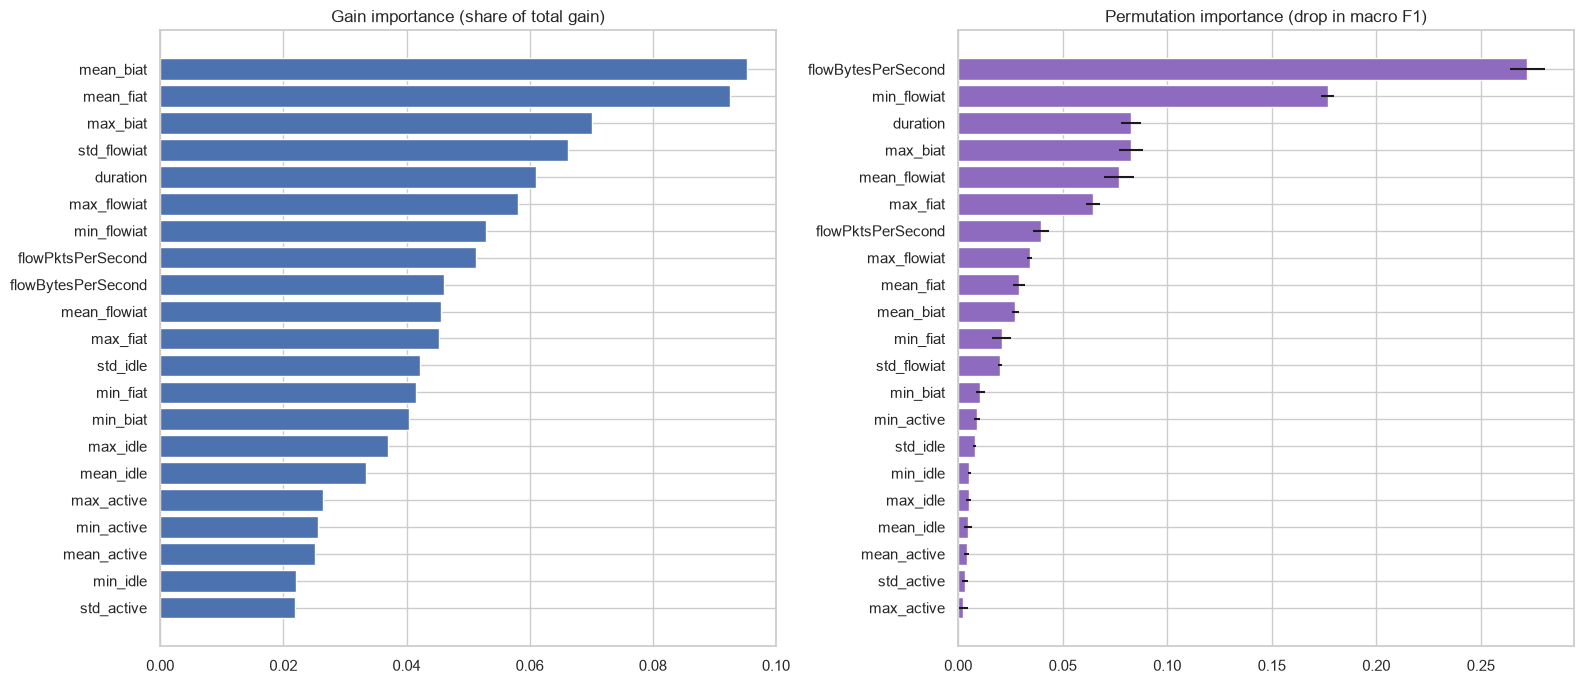

,gain_importance,permutation_mean,permutation_std
flowBytesPerSecond,0.0461,0.2722,0.0084
min_flowiat,0.0529,0.1767,0.0031
duration,0.0610,0.0826,0.0048
max_biat,0.0701,0.0825,0.0058
mean_flowiat,0.0456,0.0769,0.0071
max_fiat,0.0453,0.0645,0.0034
flowPktsPerSecond,0.0513,0.0398,0.0039
max_flowiat,0.0581,0.0341,0.0012
mean_fiat,0.0925,0.0291,0.0031
mean_biat,0.0952,0.0274,0.0016


In [23]:
gain = final_model.get_booster().get_score(importance_type="gain")
gain_imp = pd.Series({f: gain.get(f, 0.0) for f in FEATURES}, name="gain_importance")
gain_imp = gain_imp / gain_imp.sum()

perm = permutation_importance(
    final_model, X_test, y_test, scoring="f1_macro",
    n_repeats=5, random_state=SEED, n_jobs=1,
)
perm_imp = pd.DataFrame({
    "permutation_mean": perm.importances_mean,
    "permutation_std": perm.importances_std,
}, index=FEATURES)

importance_table = pd.concat([gain_imp, perm_imp], axis=1).sort_values("permutation_mean", ascending=False)
importance_table.to_csv(TAB_DIR / "feature_importance.csv")

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
order_gain = importance_table.sort_values("gain_importance")
axes[0].barh(order_gain.index, order_gain["gain_importance"], color="#4C72B0")
axes[0].set_title("Gain importance (share of total gain)")
order_perm = importance_table.sort_values("permutation_mean")
axes[1].barh(order_perm.index, order_perm["permutation_mean"], xerr=order_perm["permutation_std"], color="#8E6BBF")
axes[1].set_title("Permutation importance (drop in macro F1)")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_importance.png", dpi=200, bbox_inches="tight")
plt.show()

importance_table.round(4)

## 18. Tuned model on all four time windows

The dataset comes with four time windows: 15s, 30s, 60s and 120s. The team tested Logistic Regression on
all four, so we do the same with our tuned XGBoost. We use the same best settings found on 15s
for every window, so the comparison is fair.

  15s done  -> macro F1 = 0.8235


  30s done  -> macro F1 = 0.8140


  60s done  -> macro F1 = 0.8229


 120s done  -> macro F1 = 0.7730


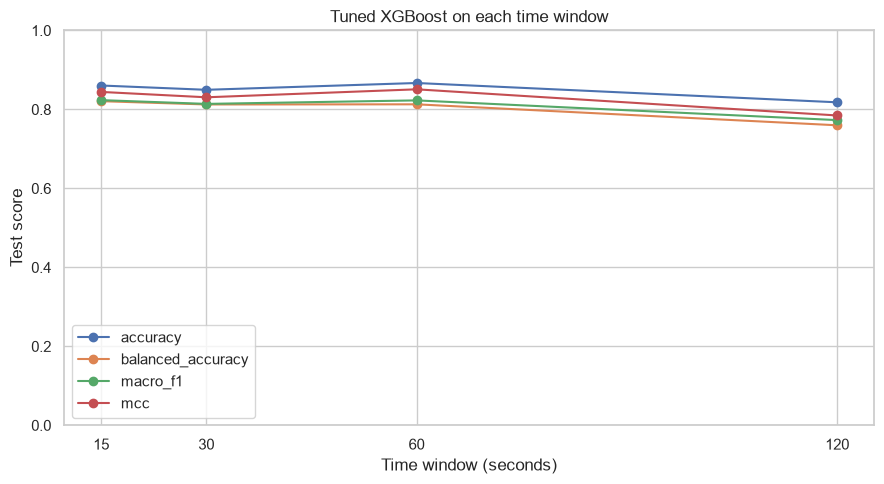

,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,train_accuracy,train_rows,test_rows
timeout,,,,,,,,,,
15,0.8606,0.8209,0.8288,0.8209,0.8235,0.8600,0.8443,0.9868,14459,3615
30,0.8497,0.8126,0.8183,0.8126,0.8140,0.8485,0.8307,0.9850,10910,2728
60,0.8669,0.8129,0.8427,0.8129,0.8229,0.8660,0.8509,0.9815,11783,2946
120,0.8180,0.7598,0.7935,0.7598,0.7730,0.8148,0.7847,0.9758,7671,1918


In [24]:
timeout_rows = []
for t in ALL_TIMEOUTS:
    tr, te = load_split(t)
    enc_t = LabelEncoder().fit(tr[TARGET])
    ytr, yte = enc_t.transform(tr[TARGET]), enc_t.transform(te[TARGET])
    weights_t = compute_sample_weight("balanced", ytr) if USE_BALANCED else None
    model_t = XGBClassifier(**{**BASE_PARAMS, "n_jobs": -1}, **model_params)
    model_t.fit(tr[FEATURES], ytr, sample_weight=weights_t)
    scores = get_scores(yte, model_t.predict(te[FEATURES]))
    scores["train_accuracy"] = accuracy_score(ytr, model_t.predict(tr[FEATURES]))
    scores["timeout"] = t
    scores["train_rows"] = len(tr)
    scores["test_rows"] = len(te)
    timeout_rows.append(scores)
    print(f"{t:>4}s done  -> macro F1 = {scores['macro_f1']:.4f}")

timeout_table = pd.DataFrame(timeout_rows).set_index("timeout")
timeout_table.to_csv(TAB_DIR / "timeout_comparison.csv")

fig, ax = plt.subplots(figsize=(9, 5))
timeout_table[["accuracy", "balanced_accuracy", "macro_f1", "mcc"]].plot(marker="o", ax=ax)
ax.set_xticks(ALL_TIMEOUTS)
ax.set_xlabel("Time window (seconds)")
ax.set_ylabel("Test score")
ax.set_title("Tuned XGBoost on each time window")
ax.set_ylim(0, 1)
plt.tight_layout()
plt.savefig(FIG_DIR / "timeout_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

timeout_table.round(4)

## 19. Compare with the team's Logistic Regression

The team saved Logistic Regression results in `reports/results/logistic_regression_timeout_comparison.csv`.
We put them next to our XGBoost results. Both models used the same train and test files,
so the comparison is fair.

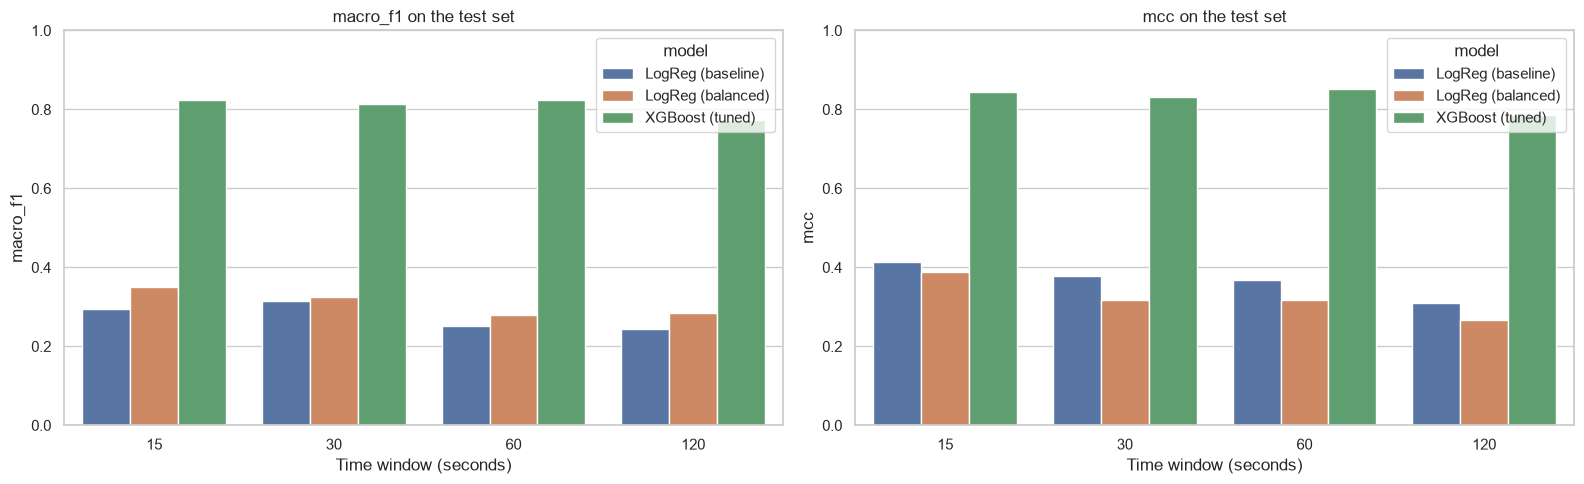

timeout,15,30,60,120
model,,,,
LogReg (balanced),0.3490,0.3244,0.2796,0.2847
LogReg (baseline),0.2950,0.3135,0.2506,0.2451
XGBoost (tuned),0.8235,0.8140,0.8229,0.7730


In [25]:
logreg_file = PROJECT_ROOT / "reports" / "results" / "logistic_regression_timeout_comparison.csv"

if logreg_file.exists():
    logreg = pd.read_csv(logreg_file)
    rows = []
    for _, r in logreg.iterrows():
        rows.append({"model": f"LogReg ({r['experiment']})", "timeout": r["timeout"],
                     "accuracy": r["accuracy"], "macro_f1": r["macro_f1"],
                     "balanced_accuracy": r["balanced_accuracy"], "mcc": r["mcc"]})
    for t, r in timeout_table.iterrows():
        rows.append({"model": "XGBoost (tuned)", "timeout": t,
                     "accuracy": r["accuracy"], "macro_f1": r["macro_f1"],
                     "balanced_accuracy": r["balanced_accuracy"], "mcc": r["mcc"]})
    model_compare = pd.DataFrame(rows)
    model_compare.to_csv(TAB_DIR / "model_comparison_with_logreg.csv", index=False)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    for ax, metric in zip(axes, ["macro_f1", "mcc"]):
        sns.barplot(data=model_compare, x="timeout", y=metric, hue="model", ax=ax)
        ax.set_title(f"{metric} on the test set")
        ax.set_xlabel("Time window (seconds)")
        ax.set_ylim(0, 1)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "model_comparison_with_logreg.png", dpi=200, bbox_inches="tight")
    plt.show()

    display(model_compare.pivot(index="model", columns="timeout", values="macro_f1").round(4))
else:
    print("Logistic Regression results file not found, skipping this step.")

## 20. Save the final model

We save the trained model **and** the label encoder together with `joblib`, plus a small JSON file
with the model details. You can load the model later like this:

```python
saved = joblib.load("reports/results/xgboost/model/xgboost_14class_15s.joblib")
model, encoder = saved["model"], saved["label_encoder"]
encoder.inverse_transform(model.predict(new_data[FEATURES]))
```

Note: the project `.gitignore` ignores `*.joblib` files, so the model file will not be pushed to git.
All other results (tables and figures) will be pushed.

In [26]:
model_path = MODEL_DIR / f"xgboost_{TASK}_{TIMEOUT}s.joblib"
joblib.dump({"model": final_model, "label_encoder": encoder, "features": FEATURES}, model_path)

model_info = {
    "model": "XGBClassifier",
    "xgboost_version": xgb.__version__,
    "task": TASK,
    "timeout_seconds": TIMEOUT,
    "features": FEATURES,
    "classes": CLASSES,
    "fixed_params": {k: v for k, v in BASE_PARAMS.items() if k != "n_jobs"},
    "best_params": best_params,
    "cv_folds": N_FOLDS,
    "cv_macro_f1_mean": float(tuned_cv_table.loc["macro_f1", "val_mean"]),
    "cv_macro_f1_std": float(tuned_cv_table.loc["macro_f1", "val_std"]),
    "test_scores": {k: float(v) for k, v in test_scores["tuned_test"].items()},
}
with open(MODEL_DIR / "model_info.json", "w") as f:
    json.dump(model_info, f, indent=2)

loaded = joblib.load(model_path)
print("Model saved to:", model_path)
print("Loaded model gives the same test macro F1:",
      round(f1_score(y_test, loaded["model"].predict(X_test), average="macro"), 4))

Model saved to: C:\Users\suner\Downloads\ml\ML-Traffic-Classification\reports\results\xgboost\model\xgboost_14class_15s.joblib
Loaded model gives the same test macro F1: 0.8235


## 21. Final summary

The cell below prints the main numbers and lists every file saved in the results folder.

In [27]:
print("=" * 60)
print(f"XGBOOST - {TASK} - {TIMEOUT}s")
print("=" * 60)
print("Best settings:", best_params)
print()
print(f"CV macro F1     : {tuned_cv_table.loc['macro_f1', 'val_mean']:.4f} +/- {tuned_cv_table.loc['macro_f1', 'val_std']:.4f}")
print(f"Test accuracy   : {test_scores.loc['accuracy', 'tuned_test']:.4f}")
print(f"Test bal. acc.  : {test_scores.loc['balanced_accuracy', 'tuned_test']:.4f}")
print(f"Test macro F1   : {test_scores.loc['macro_f1', 'tuned_test']:.4f}")
print(f"Test MCC        : {test_scores.loc['mcc', 'tuned_test']:.4f}")
print()
print("Saved files:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(PROJECT_ROOT))

XGBOOST - 14class - 15s
Best settings: {'subsample': 0.6, 'reg_lambda': 5, 'reg_alpha': 0.5, 'n_estimators': 400, 'min_child_weight': 3, 'max_depth': 10, 'learning_rate': 0.2, 'gamma': 0, 'colsample_bytree': 0.7, 'sample_weight': 'none'}

CV macro F1     : 0.8223 +/- 0.0080
Test accuracy   : 0.8606
Test bal. acc.  : 0.8209
Test macro F1   : 0.8235
Test MCC        : 0.8443

Saved files:
   reports\results\xgboost\best_params.json
   reports\results\xgboost\figures\baseline_vs_tuned_cv.png
   reports\results\xgboost\figures\boosting_curve.png
   reports\results\xgboost\figures\class_counts.png
   reports\results\xgboost\figures\confusion_matrix.png
   reports\results\xgboost\figures\cv_folds.png
   reports\results\xgboost\figures\feature_importance.png
   reports\results\xgboost\figures\learning_curve.png
   reports\results\xgboost\figures\model_comparison_with_logreg.png
   reports\results\xgboost\figures\per_class_scores.png
   reports\results\xgboost\figures\timeout_comparison.png
   

## 22. Conclusion

**What we did**

- Trained an XGBoost model to classify 14 types of network traffic from 21 time-based flow features.
- Used group-aware 5-fold cross validation, so the same flow never appears in both the training and validation part.
- Tuned the model with randomized search and picked the best setting by macro F1.
- Checked if balanced class weights help, using cross validation.
- Checked the model with learning curves, a boosting curve and three validation curves.
- Tested the final model once on the hold-out test set.

**How to read the results**

- Look at `tables/test_scores.csv` for the final scores, and compare tuned vs baseline.
- The **learning curve** shows if more data would help (validation line still going up) and how big the overfitting gap is.
- The **boosting curve** shows how the error changes as more trees are added, and where adding trees stops helping.
- The **validation curves** show how the number of trees, tree depth and learning rate change overfitting and underfitting.
- The **confusion matrix** shows which classes are mixed up. Normal and VPN versions of the same app type
  (for example `BROWSING` and `VPN-BROWSING`) and similar apps (for example `CHAT` and `FT`) are usually the hardest.
- The **timeout comparison** shows which time window works best for this model.
- The **comparison with Logistic Regression** shows how much a boosted tree model improves on the team's linear baseline.

All tables, figures and the saved model are in `reports/results/xgboost/`.